# 02a Initialization from QuPath exports

This notebook is used to turn a collection of .csv files exported from QuPath to a single CSV file. Along the way, we will do binary marker rule-based cell annotation based on a provided annotation strategy (marker combos) and section the samples if multiple sections are used.

### Imports (run first)

In [1]:
import pandas as pd
import os
import warnings

os.chdir('../Quantcell')
from codex_project import codex_project, replace_marker_match_centroids, read_marker_combos, get_marker_list
warnings.filterwarnings('ignore')

### Parameters
annotations_path  
> .json annotations

base_dir  
> location of base directory, should include raw_data folder w/ project folders inside

project_name
> name of project, will create a folder with this name in the base directory

project_folders
> list of folders with marker data inside to be used for this project (names of folders are not used)

sample_labels
> dict relating project_folders names to a label, will be in 'Parent' column (typically this is used to show mouse information)

In [2]:
annotations_path = '../marker_combos_062525_updated_verified.json'   
base_dir = '../Output' 
project_name = 'QuantCellPaperO3'
project_path = f'{base_dir}/{project_name}'
data_path = f'../sample_data'

project_folders = ['QuantCellPaperO3']

sample_labels = {'QuantCellPaperO3':'QuantCellPaperO3'}


Initialize the codex_project object from the marker .csv files. If there are multiple projects together, you can label them using the name of the folder in which all of the .csv files are found in.

In [3]:
os.makedirs(project_path, exist_ok=True)

codex = codex_project()
codex.initialize(data_path=data_path, folders=project_folders, project_name=project_name, annotation_strategy_path=annotations_path)
codex.set_sample_labels(sample_labels)

Ensure that all of the required .csv files for every marker in marker_combos has been found. If any are not present or there are any extra, it will state them here.

In [4]:
codex.verify_marker_annotations()

~~~Verifying markers in ../sample_data/QuantCellPaperO3~~~
Missing markers: []
Unused markers: []



True

Annotate cell types using the rule-based strategy (the marker combinations). Any cell matching more than one cell type will be left unannotated ("Other").

drop_missing params:
 - max_missing_per_row: int = 2 # drop columns with more than X NAs
 - max_missing_per_col: int = 100 # drop rows with more than X NAs
 - drop_axis=0 # if there are any remaining NAs, 0 to drop cells (rows), 1 to drop features (columns)

In [5]:
codex.annotate()
codex.drop_missing(max_missing_per_col=1000000)

OLD DIMENSIONS: (42434, 549)
NEW DIMENSIONS: (42434, 549)


Sanity check to make sure every cell type defined is present at last once

In [6]:
assert(len(codex.codex.loc[:, 'cell_type'].unique()) == len(codex._marker_combos.keys())+1)

If spatial location is specified and you have different samples you want to keep separate spatially, do that here.

First, DBSCAN is used to find all clusters. Use visualize_sectioning to see if you need to adjust eps

In [7]:
codex.section_samples(eps=500)

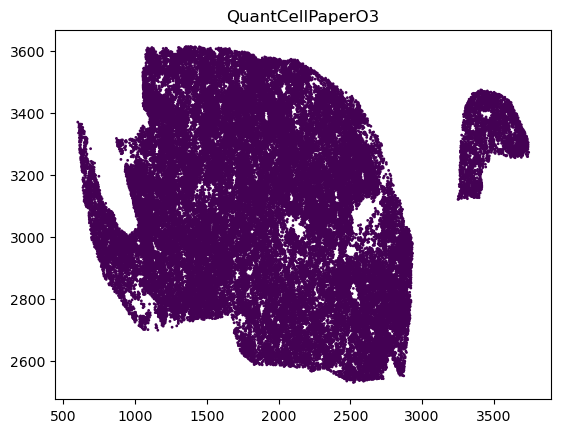

In [8]:
#codex.override_sectioning() # replace all sections with the name of the data folder + _0 if you want to override sectioning
codex.visualize_sectioning()

Verify every cell is assigned to a section

In [9]:
codex.verify_sectioning()

~~~Verifying sectioning~~~
Passed: All cells assigned in QuantCellPaperO3


True

Save to .csv file, it is now ready for QuantCell

In [10]:
codex.save_csv(f'{project_path}/codex_rule_based_{project_name}.csv')

# Load in
Includes all data except the folders in which the raw data is

In [11]:
other_codex = codex_project()
other_codex.read_csv(f'{project_path}/codex_rule_based_{project_name}.csv', project_name=project_name)
other_codex.read_annotation_strategy(annotations_path)